In [1]:
from datetime import datetime
from collections import defaultdict
import pandas as pd
import numpy as np
from scipy.signal import argrelextrema
import matplotlib.pyplot as plt 
from alpaca.trading.client import TradingClient
from alpaca.trading.requests import GetAssetsRequest
from alpaca.trading.enums import AssetClass
from alpaca.data.timeframe import TimeFrame
from alpaca.data.historical import StockHistoricalDataClient, OptionHistoricalDataClient
from alpaca.data.requests import StockLatestQuoteRequest, StockBarsRequest

trading_client = TradingClient('PKMDAQ4V5CCOOPF8BUUR', 'HjCdK5Cgsr7vTMCveXibh4txCY1VjBfQvO6Ggw68')

# Get account information.
account = trading_client.get_account()

# Check if our account is restricted from trading.
if account.trading_blocked: # type: ignore
    print('Account is currently restricted from trading.')

# print(f'{account.buying_power} is available as buying power.') # type: ignore

# Check current balance vs. balance at the last market close
balance_change = float(account.equity) - float(account.last_equity) # type: ignore
# print(f'Today\'s portfolio balance change: ${balance_change}')

# search for US equities
search_params = GetAssetsRequest(asset_class=AssetClass.US_EQUITY)

assets = trading_client.get_all_assets(search_params)

type(assets[1]) # type: ignore

# print(assets[1].asset_class) # type: ignore

# search for AAPL
aapl_asset = trading_client.get_asset('AAPL')

# print(aapl_asset)
# if aapl_asset.tradable: # type: ignore
#     print('We can trade AAPL.')

In [2]:
stock_client = StockHistoricalDataClient('PKMDAQ4V5CCOOPF8BUUR', 'HjCdK5Cgsr7vTMCveXibh4txCY1VjBfQvO6Ggw68')

option_client = OptionHistoricalDataClient('PKMDAQ4V5CCOOPF8BUUR', 'HjCdK5Cgsr7vTMCveXibh4txCY1VjBfQvO6Ggw68')

# multi symbol request - single symbol is similar
multisymbol_request_params = StockLatestQuoteRequest(symbol_or_symbols=["SPY", "GLD", "TLT"])

latest_multisymbol_quotes = stock_client.get_stock_latest_quote(multisymbol_request_params)

gld_latest_ask_price = latest_multisymbol_quotes["GLD"].ask_price

print(gld_latest_ask_price)


444.96


In [3]:
# Set up the parameters
request_params = StockBarsRequest(
    symbol_or_symbols=["AAPL","GOOG"],
    timeframe=TimeFrame.Hour, # type: ignore
    start=datetime(2021, 1, 1),
    end=datetime(2021, 1, 10)
)

# Get the stock data
bars = stock_client.get_stock_bars(request_params)

# Convert it to a dataframe
bars_df = bars.df # type: ignore

# Sample print statement
print(bars["AAPL"][1].close)

bars_df.head()

# Get just the Apple data
prices = bars_df.loc["AAPL"]
prices.head()



133.6


,open,high,low,close,volume,trade_count,vwap
timestamp,,,,,,,
2021-01-01 00:00:00+00:00,132.69,132.80,132.65,132.71,87628.0,697.0,132.716197
2021-01-04 09:00:00+00:00,133.31,134.01,133.02,133.60,112129.0,1256.0,133.674265
2021-01-04 10:00:00+00:00,133.60,134.43,133.43,134.30,163257.0,1124.0,134.042261
2021-01-04 11:00:00+00:00,134.22,134.35,133.60,133.99,45136.0,688.0,134.163240
2021-01-04 12:00:00+00:00,133.92,134.00,133.54,133.95,494894.0,5730.0,133.792978


In [4]:
print(type(bars))
print(bars["AAPL"][1].close)
print(type(bars["AAPL"]))
print(type(bars["AAPL"][1]))
print(bars["AAPL"][1])

<class 'alpaca.data.models.bars.BarSet'>
133.6
<class 'list'>
<class 'alpaca.data.models.bars.Bar'>
symbol='AAPL' timestamp=datetime.datetime(2021, 1, 4, 9, 0, tzinfo=TzInfo(UTC)) open=133.31 high=134.01 low=133.02 close=133.6 volume=112129.0 trade_count=1256.0 vwap=133.674265


In [5]:


def get_max_min(prices, smoothing, window_range):
    smooth_prices = prices['close'].rolling(window=smoothing).mean().dropna()
    local_max = argrelextrema(smooth_prices.values, np.greater)[0]
    local_min = argrelextrema(smooth_prices.values, np.less)[0]
    price_local_max_dt = []
    for i in local_max:
        if (i>window_range) and (i<len(prices)-window_range):
            price_local_max_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmax())
    price_local_min_dt = []
    for i in local_min:
        if (i>window_range) and (i<len(prices)-window_range):
            price_local_min_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmin())  
    maxima = pd.DataFrame(prices.loc[price_local_max_dt])
    minima = pd.DataFrame(prices.loc[price_local_min_dt])
    max_min = pd.concat([maxima, minima]).sort_index()
    max_min.index.name = 'date'
    max_min = max_min.reset_index()
    max_min = max_min[~max_min.date.duplicated()]
    p = prices.reset_index()   
    max_min['day_num'] = p[p['timestamp'].isin(max_min.date)].index.values
    max_min = max_min.set_index('day_num')['close']
    
    return max_min


In [6]:
smoothing = 3
window_range = 5

smooth_prices = prices['close'].rolling(window=smoothing).mean().dropna() # Pandas Series
# print(type(smooth_prices))
# print(smooth_prices.head(20))
local_max = argrelextrema(smooth_prices.values, np.greater)[0] # numpy ndarray
local_min = argrelextrema(smooth_prices.values, np.less)[0] # numpy ndarray
# print(type(local_max))
# print(local_max[0:5])
# print(local_min[0:5])
price_local_max_dt = [] # List
for i in local_max:
    if (i>window_range) and (i<len(prices)-window_range):
        price_local_max_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmax())
# print(type(price_local_max_dt))
# print(price_local_max_dt[0:5])  
price_local_min_dt = [] # List
for i in local_min:
    if (i>window_range) and (i<len(prices)-window_range):
        price_local_min_dt.append(prices.iloc[i-window_range:i+window_range]['close'].idxmin())
# print(price_local_min_dt[0:5])  
maxima = pd.DataFrame(prices.loc[price_local_max_dt]) # pandas DataFrame
minima = pd.DataFrame(prices.loc[price_local_min_dt])
# print(maxima.head())
# print(minima.head())
max_min = pd.concat([maxima, minima]).sort_index()
max_min.index.name = 'date'
max_min = max_min.reset_index()
max_min = max_min[~max_min.date.duplicated()]
p = prices.reset_index()   
max_min['day_num'] = p[p['timestamp'].isin(max_min.date)].index.values
max_min = max_min.set_index('day_num')['close']


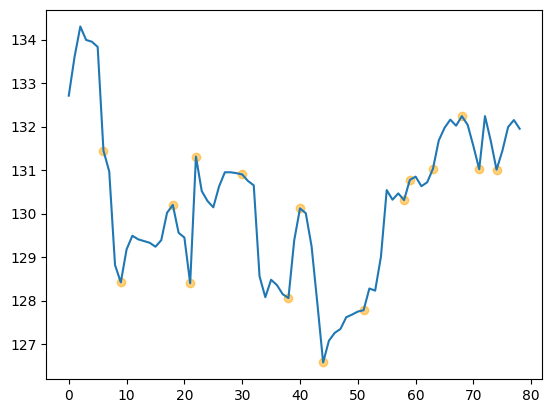

In [7]:
prices.reset_index()['close'].plot()
plt.scatter(max_min.index, max_min.values, color='orange', alpha=0.5) # type: ignore

In [8]:
# A > B,C,D
# B,D < C
# abs(B-D) < np.mean([B,D]) * 0.05

def find_patterns(max_min):  
    patterns = defaultdict(list)
    
    # Window range is 4 units
    for i in range(4, len(max_min)):  
        window = max_min.iloc[i-4:i]
        
        # Pattern must play out in less than n units
        if window.index[-1] - window.index[0] > 100:      
            continue   
            
        a, b, c, d = window.iloc[0:4]
                
        # IHS
        # if a<strong and c<a and c<e and c<d and e<d and abs(b-d)<=np.mean([b,d])*0.02:
        #        patterns['IHS'].append((window.index[0], window.index[-1]))
        
        # double bottom 
        if a>b and a>c and a > d and b<c and d<c and abs(b-d)<=np.mean([b,d])*0.05:
            patterns['DB'].append((window.index[0], window.index[-1]))
        
    return patterns

patterns = find_patterns(max_min)
print(patterns['DB'])

[(np.int64(6), np.int64(21)), (np.int64(30), np.int64(44))]


DB [(np.int64(6), np.int64(21)), (np.int64(30), np.int64(44))]
0 (np.int64(6), np.int64(21))
1 (np.int64(30), np.int64(44))


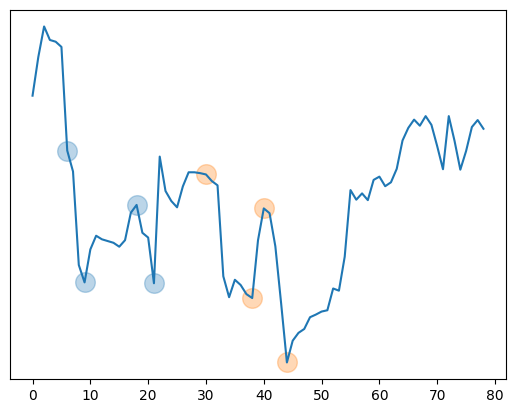

In [9]:
prices.reset_index()['close'].plot()
for name, end_day_nums in patterns.items():
    print(name, end_day_nums)
    for i, tup in enumerate(end_day_nums):
        print(i, tup)
        start_data = tup[0]
        end_data = tup[1]
        plt.scatter(max_min.loc[start_data:end_data].index,
            max_min.loc[start_data:end_data].values, # type: ignore
            s=200, alpha=.3)
        plt.yticks([])
        